# 05 · Funding rates: BTC and ETH perpetuals on Binance, 2019–2026

Module **M7: funding rate** (Phase 0).

**Task.** Download the complete funding-rate history of two Binance perpetuals, check the data
(intervals, gaps, units), annualize it correctly, describe how often funding sits at its default
value, and zoom into the 10/10/2025 crash to revisit two loose ends of notebook 04 (the perp
trading below spot, and the funding cost that 04 only assumed).

**Market.** Binance USDⓈ-M perpetuals **BTCUSDT** and **ETHUSDT** (ccxt exchange `binanceusdm`,
symbols `BTC/USDT:USDT`, `ETH/USDT:USDT`). Endpoint `GET /fapi/v1/fundingRate` (public, no API key).

**Hypothesis (lab rule 1).** *I believe the funding of BTCUSDT and ETHUSDT is exactly the default
0.01% per 8 h most of the time, because Binance's formula has a "dead zone" that absorbs small
premiums. I believe it moves away from 0.01% when demand for leverage is one-sided: above it in
bull runs (many traders want to be long with leverage and pay for it) and below it, even negative,
after crashes (longs are wiped out and shorts become the crowded side).*

**What funding is.** A perpetual never expires, so nothing forces its price to meet the spot
price. Every 8 hours one side pays the other: **payment = notional (at the mark price) × rate**.
A positive rate means **longs pay shorts**; a negative rate means shorts pay longs.

**How Binance sets the rate** (context, not recomputed here except in Q7):

$$F = \bar P + \text{clamp}(I - \bar P,\ -0.05\%,\ +0.05\%)\quad\text{(divided by } 8/N \text{ for } N\text{-hour intervals)}$$

with $\bar P$ the average premium of the perp over the index during the interval and
$I = 0.01\%$ per 8 h the interest component. If $-0.04\% \le \bar P \le +0.06\%$, the clamp absorbs
the difference and $F$ is **exactly 0.01%**: the **dead zone**. Since **2025-09-18 08:01 UTC** the
formula divides by $8/N$ for intervals other than 8 h (no effect on 8-hour symbols) and "Price 2"
of the mark price uses a 30-second basis.

## 1. Setup and parameters

**Fixed before looking at the data** (lab rule 4). Changes after inspection are labeled
**post-inspection**.

- History window (UTC, start included, end excluded): **2019-01-01 → 2026-11-17 00:00**. The start
  is before Binance USDⓈ-M existed, so the first record is *found*, not assumed; the end is fixed
  so reruns return the same rows.
- Zoom window (Q6): every payment from **2025-09-15 00:00 to 2025-10-31 16:00** UTC. "Before the
  crash" means a payment time earlier than **2025-10-10 20:50 UTC** (start of the crash window of
  notebook 04).
- Notebook 04 window (Q7, Q8): **2025-10-09 00:00 → 2025-10-11 00:00** UTC; margin 1,000 USDT,
  leverage 5x / 10x / 20x (notional 5,000 / 10,000 / 20,000 USDT), MMR 0.40%, cum 0, assumed
  funding 0.01% per payment.
- Annualization: **simple**, rate × (8,760 / interval hours of that record), 365-day year.
- "Exactly 0.01%": compared on the API's text with `Decimal`; tolerance sweep 0, 1e-9, 1e-7, 1e-6
  (in rate units: 1e-6 = 0.0001 percentage points = 1% of the baseline).

In [1]:
import sys
import time
from decimal import Decimal
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.data.bitstamp import load_or_fetch_json
from src.data.candles import to_utc
from src.data.funding import (FUNDING_MAX_LIMIT, fetch_funding_window, funding_cache_path,
                              load_or_fetch_funding)
from src.data.ohlcv import cache_path, fetch_ohlcv_window, load_or_fetch_window, make_exchange
from src.funding import (BASELINE_RATE, annualize_compound, annualize_simple,
                         binance_funding_from_premium, funding_payment, infer_intervals,
                         is_baseline, sign_shares, total_funding_paid)
from src.liquidation import simulate_isolated_longs

HISTORY_START, HISTORY_END = to_utc("2019-01-01"), to_utc("2026-11-17 00:00")
SYMBOLS = {"BTCUSDT": "BTC/USDT:USDT", "ETHUSDT": "ETH/USDT:USDT"}  # API id: ccxt symbol
ZOOM_START, ZOOM_END = to_utc("2025-09-15 00:00"), to_utc("2025-11-01 00:00")  # end excluded
CRASH_START = to_utc("2025-10-10 20:50")       # crash window start used in notebook 04
W04_START, W04_END = to_utc("2025-10-09 00:00"), to_utc("2025-10-11 00:00")
LEVERAGES, MARGIN, MMR, CUM = [5, 10, 20], 1_000.0, 0.004, 0.0
NOTIONALS = {lev: MARGIN * lev for lev in LEVERAGES}  # 5,000 / 10,000 / 20,000 USDT
ASSUMED_RATE = 0.0001                           # notebook 04's assumption, per payment
TOLERANCES = [0.0, 1e-9, 1e-7, 1e-6]
EVENTS = {"Terra/UST": "2022-05-09", "FTX": "2022-11-08",
          "formula change": "2025-09-18 08:01", "10/10 crash": "2025-10-10 21:00"}
CACHE_DIR = REPO_ROOT / "data" / "raw" / "05_funding_rates"
CACHE_04 = REPO_ROOT / "data" / "raw" / "04_liquidation_math"   # reused, refetched if missing

COLORS = {"BTCUSDT": "#2a78d6", "ETHUSDT": "#eb6834"}  # fixed per symbol (same blue/orange as 04)
INK, MUTED, GRID = "#2b2b2a", "#6b6a64", "#e4e2dc"
pd.set_option("display.width", 120)


def ms(ts):
    return int(to_utc(ts).timestamp() * 1000)


def fmt(ts):
    return f"{ts:%Y-%m-%d %H:%M}"

## 2. Step 0 · Check the source before using it

Documentation (read 2026-11-17):
[Get Funding Rate History](https://developers.binance.com/docs/derivatives/usds-margined-futures/market-data/rest-api/Get-Funding-Rate-History),
[Get Funding Rate Info](https://developers.binance.com/docs/derivatives/usds-margined-futures/market-data/rest-api/Get-Funding-Rate-Info).
It says: `limit` default 100, max 1000; oldest first; without a range it returns the latest 200;
limit 500 requests / 5 min / IP shared with `fundingInfo`.

We **measure** instead of trusting it, through ccxt's raw method `fapiPublicGetFundingRate` (sends
our parameters unchanged) and ccxt's unified `fetch_funding_rate_history`. Each request is followed
by a 0.7 s pause. Results are cached in `data/` (delete the file to measure again).

Rows of the table: page sizes; what `startTime=0` returns; the first record and how many rows
exist **before** it (asking with only `endTime = first − 1 ms`, which returns the latest rows
before that time); order; fields; and whether ccxt's unified method caps the page or loses fields.

In [2]:
def check_funding_source():
    ex = make_exchange("binanceusdm")
    raw = ex.fapiPublicGetFundingRate
    utc = lambda x: str(pd.to_datetime(int(x), unit="ms", utc=True))
    start = ms("2019-01-01")

    def call(params):
        time.sleep(0.7)  # stay far below 500 requests / 5 min
        try:
            return raw(params)
        except Exception as error:  # report, do not hide
            return f"error: {str(error)[-60:]}"

    checks = {}
    for sym, ccxt_symbol in SYMBOLS.items():
        sizes = {lim: call({"symbol": sym, "startTime": start, **({"limit": lim} if lim else {})})
                 for lim in (None, 1000, 1500)}
        page = sizes[1000]
        zero = call({"symbol": sym, "startTime": 0, "limit": 1000})
        first = int(page[0]["fundingTime"])
        before = call({"symbol": sym, "endTime": first - 1, "limit": 1000})
        no_range = call({"symbol": sym})
        time.sleep(0.7)
        unified = ex.fetch_funding_rate_history(ccxt_symbol, since=start, limit=1000)
        stamps = [int(r["fundingTime"]) for r in page]
        checks[sym] = {
            "rows: no limit / 1000 / 1500": " / ".join(
                str(len(v)) if isinstance(v, list) else v for v in sizes.values()),
            "rows with no range at all": len(no_range),
            "startTime=0 → rows, first (UTC)": f"{len(zero)}, {utc(zero[0]['fundingTime'])}",
            "first record (UTC)": utc(first),
            "rows before the first record": len(before),
            "oldest first": stamps == sorted(stamps),
            "fields": ", ".join(page[0].keys()),
            "fundingRate type": type(page[0]["fundingRate"]).__name__,
            "empty markPrice in 1st page": sum(r["markPrice"] == "" for r in page),
            "ccxt unified: rows (limit 1000)": len(unified),
            "ccxt unified: rateType & markPrice in info": all(
                {"rateType", "markPrice"} <= set(r["info"]) for r in unified),
            "checked at (UTC)": str(pd.Timestamp.now(tz="UTC").floor("s")),
        }
    time.sleep(0.7)
    info = ex.fapiPublicGetFundingInfo()
    checks["fundingInfo"] = {"symbols listed": len(info),
                             **{sym: next((x for x in info if x["symbol"] == sym), "not listed")
                                for sym in SYMBOLS}}
    return checks


source_checks = load_or_fetch_json(CACHE_DIR / "source_checks.json", check_funding_source)
pd.DataFrame({sym: source_checks[sym] for sym in SYMBOLS})

,BTCUSDT,ETHUSDT
rows: no limit / 1000 / 1500,"100 / 1000 / error: :""illegal params."",""data"":...","100 / 1000 / error: :""illegal params."",""data"":..."
rows with no range at all,100,100
"startTime=0 → rows, first (UTC)","500, 2026-06-04 08:00:00+00:00","500, 2026-06-04 08:00:00+00:00"
first record (UTC),2019-09-10 08:00:00+00:00,2019-11-27 08:00:00+00:00
rows before the first record,0,0
oldest first,True,True
fields,"symbol, fundingTime, fundingRate, markPrice, r...","symbol, fundingTime, fundingRate, markPrice, r..."
fundingRate type,str,str
empty markPrice in 1st page,1000,1000
ccxt unified: rows (limit 1000),1000,1000


How to read it: one column per symbol, one measured property per row. `rows: no limit / 1000 /
1500` are the page sizes returned when asking for the default, 1000 and 1500 rows (an `error` means
the API rejects the value instead of capping it). `startTime=0` shows what comes back when the
start is the Unix epoch. `rows before the first record` should be 0 if the first record is truly
the first.

**Technical sheet (same format as notebooks 03 and 04).**

| | Binance USDⓈ-M `GET /fapi/v1/fundingRate` |
|---|---|
| Max per request | **1000** (1500 → error "illegal params") |
| Default | **100**, with `startTime` and also with no range at all (the docs say 200 for the latter) |
| Timestamp | `fundingTime`, **ms**, UTC; often a few ms after the hour |
| Order | oldest first; `startTime` inclusive |
| Trap | **`startTime=0` is ignored**: the API returns the *latest* rows. `src/` refuses `start_ms <= 0` |
| First record | BTCUSDT 2019-09-10 08:00 UTC, ETHUSDT 2019-11-27 08:00 UTC (see table) |
| Fields | symbol, fundingTime, fundingRate (**string**), markPrice (string, `""` in old rows), rateType |
| ccxt | unified method keeps 1000 rows and the raw fields in `info`; we use the raw method (one row in = one row out) |

We download with `src/data/funding.py`: pages of 1000, `startTime = last fundingTime + 1 ms`,
0.7 s between pages, cached to a separate `_funding` Parquet file whose stored window must match
the requested one exactly.

## 3. Q1 · Data: the complete history

`fetch_funding_window` keeps rows with time in `[2019-01-01, 2026-11-17)`, drops exact
duplicates (and raises on conflicting ones), counts and drops `rateType == "Special"`, and never
fills anything. Then we add, per record: the interval since the previous record (Q2), the offset
from the exact hour, and the simple annualized rate (Q3). The first record has no previous one;
its interval is set to 8 h (the value every other record has, checked in Q2).

In [3]:
def download(sym):
    exchange = make_exchange("binanceusdm")
    return fetch_funding_window(exchange.fapiPublicGetFundingRate, sym, HISTORY_START, HISTORY_END)


funding, infos = {}, {}
for sym in SYMBOLS:
    path = funding_cache_path(CACHE_DIR, "binanceusdm", sym, "2019-01-01_2026-11-17")
    df, infos[sym] = load_or_fetch_funding(path, lambda sym=sym: download(sym),
                                           HISTORY_START, HISTORY_END)
    assert str(df.index.tz) == "UTC" and df.index.is_unique and df.index.is_monotonic_increasing
    iv = infer_intervals(df["funding_time_ms"]).set_axis(df.index)
    df = df.join(iv)
    hour_ms = 3_600_000
    df["offset_ms"] = (df["funding_time_ms"] + hour_ms // 2) % hour_ms - hour_ms // 2  # signed
    df["hours_for_ann"] = df["interval_hours"].fillna(8.0)   # first record: see the text above
    df["ann_simple"] = annualize_simple(df["funding_rate"], df["hours_for_ann"])
    df["is_baseline"] = is_baseline(df["funding_rate_str"], 0.0)   # exact, with Decimal
    funding[sym] = df

quality = {}
for sym, df in funding.items():
    first, last = df.index[0], df.index[-1]
    expected = round((df["funding_time_ms"].iloc[-1] - df["funding_time_ms"].iloc[0]) / (8 * 3_600_000)) + 1
    empty_mark = df["mark_price"].isna()
    quality[sym] = {
        "first record (UTC)": str(first), "last record (UTC)": str(last),
        "rows received": infos[sym]["rows_received"], "rows kept": len(df),
        "expected if one every 8 h": expected,
        "duplicates dropped": infos[sym]["duplicates_dropped"],
        "outside window": infos[sym]["outside_window"],
        "Special dropped": infos[sym]["special_dropped"],
        "gaps (interval > 8 h)": int((df["interval_hours_rounded"] > 8).sum()),
        "empty markPrice": int(empty_mark.sum()),
        "last empty markPrice (UTC)": str(df.index[empty_mark][-1]) if empty_mark.any() else "—",
        "rows off the exact hour": int((df["offset_ms"] != 0).sum()),
        "offset range (ms)": f"{df['offset_ms'].min()} to {df['offset_ms'].max()}",
    }
pd.DataFrame(quality)

,BTCUSDT,ETHUSDT
first record (UTC),2019-09-10 08:00:00+00:00,2019-11-27 08:00:00+00:00
last record (UTC),2026-11-16 16:00:00.004000+00:00,2026-11-16 16:00:00.004000+00:00
rows received,7874,7640
rows kept,7874,7640
expected if one every 8 h,7874,7640
duplicates dropped,0,0
outside window,0,0
Special dropped,0,0
gaps (interval > 8 h),0,0
empty markPrice,4536,4302


How to read it: one column per symbol. `expected if one every 8 h` is (last − first) / 8 h + 1;
if it equals `rows kept`, there is no missing payment. `gaps` counts intervals longer than 8 h
(rounded). `empty markPrice` rows are old records where the API sends `""`; they only matter where
we need the mark (Q8, October 2025). `offset range` is how many ms before (−) or after (+) the
exact hour the timestamps fall.

## 4. Q2 · Intervals (not assumed to be 8 h)

For every record: the raw difference with the previous `fundingTime` in ms, and the same rounded
to the nearest hour **only to classify it**. Table: number of intervals of each rounded length, by
symbol and calendar year, plus the smallest and largest raw interval in that group, written as
the deviation from exactly 8 h in ms.

In [4]:
rows = []
for sym, df in funding.items():
    d = df.dropna(subset=["interval_ms"])
    for (year, hours), g in d.groupby([d.index.year, "interval_hours_rounded"]):
        dev = g["interval_ms"] - 8 * 3_600_000
        rows.append({"symbol": sym, "year": year, "interval (h, rounded)": int(hours),
                     "count": len(g), "min deviation from 8 h (ms)": int(dev.min()),
                     "max deviation from 8 h (ms)": int(dev.max())})
intervals = pd.DataFrame(rows).set_index(["symbol", "year", "interval (h, rounded)"])

for sym, df in funding.items():   # stop condition: a non-8 h interval changes the annualization
    other = df["interval_hours_rounded"].dropna()
    other = other[other != 8]
    assert other.empty, f"STOP: {sym} has {len(other)} intervals != 8 h, first at {other.index[0]}"
intervals

count  min deviation from 8 h (ms)  max deviation from 8 h (ms)
symbol  year interval (h, rounded)                                                                 
BTCUSDT 2019 8                        337                           -8                            6
        2020 8                       1098                          -45                           36
        2021 8                       1095                          -39                           47
        2022 8                       1095                          -31                           28
        2023 8                       1095                          -28                           26
        2024 8                       1098                          -15                           13
        2025 8                       1095                          -16                           16
        2026 8                        960                          -26                           16
ETHUSDT 2019 8                        103                           -8                            6
        2020 8                       1098                          -45                           36
        2021 8                       1095                          -39                           47
        2022 8                       1095                          -31                           28
        2023 8                       1095                          -28                           26
        2024 8                       1098                          -15                           13
        2025 8                       1095                          -16                           16
        2026 8                        960                          -26                           16

How to read it: each row is one (symbol, year, rounded interval) group. If a year had, say,
4-hour intervals, it would appear as an extra row with `interval (h, rounded) = 4`. The two
deviation columns show how far the raw intervals are from exactly 28,800,000 ms (8 h); a few ms
either way comes from the timestamp offsets seen in Q1, not from a different schedule. The `assert`
above the table stops the notebook if any interval is not 8 h.

## 5. Q3 · Annualization: simple vs compound

Per record, **simple**: `rate × 8,760 / interval_hours` (8,760 hours in a 365-day year, so 1,095
payments for 8-hour intervals). **Compound**: `(1 + rate)^1,095 − 1`, which assumes each payment is
reinvested at the same rate. The rest of the notebook uses the simple version, which is how
exchanges and dashboards quote funding.

In [5]:
ann = pd.DataFrame([{"rate per 8 h (%)": 100 * r,
                     "simple (%/yr)": 100 * annualize_simple(r, 8),
                     "compound (%/yr)": 100 * annualize_compound(r, 8)} for r in (0.0001, 0.0003, 0.0005)])
ann["compound − simple (pp)"] = ann["compound (%/yr)"] - ann["simple (%/yr)"]
ann.round(3).set_index("rate per 8 h (%)")

,simple (%/yr),compound (%/yr),compound − simple (pp)
rate per 8 h (%),,,
0.01,10.95,11.571,0.621
0.03,32.85,38.881,6.031
0.05,54.75,72.869,18.119


How to read it: each row is one constant funding rate held for a whole year. Units: % per 8 h in
the index, % per year in the columns, percentage points (pp) in the last column. The gap between the
two methods grows with the rate because compounding earns "interest on interest".

## 6. Q4 · The whole history

Daily mean of the simple annualized rate (mean of the 3 payments of each UTC day), and its 7-day
moving average (trailing: each point uses that day and the 6 before it). Dashed vertical lines:
Terra/UST (2022-05-09), FTX (2022-11-08), Binance's formula change (2025-09-18 08:01) and the 10/10
crash (2025-10-10 21:00). The dotted horizontal line is the baseline 0.01% per 8 h = 10.95%/yr.

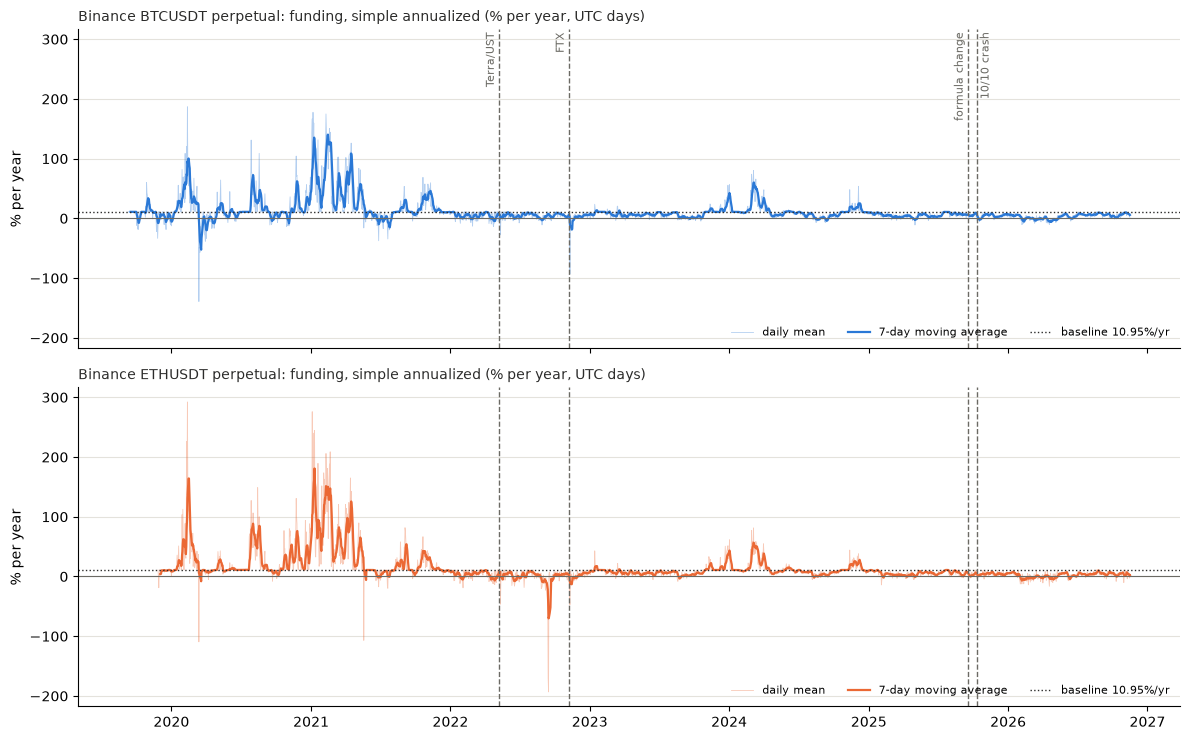

BTCUSDT daily mean: min -139.2%/yr on 2020-03-13, max 186.9%/yr on 2020-02-12
ETHUSDT daily mean: min -193.2%/yr on 2022-09-15, max 292.2%/yr on 2020-02-12


In [6]:
daily = pd.DataFrame({sym: df["ann_simple"].resample("1D").mean() for sym, df in funding.items()}) * 100
ma7 = daily.rolling(7, min_periods=7).mean()

fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, sharey=True)
for ax, sym in zip(axes, SYMBOLS):
    ax.plot(daily.index, daily[sym], color=COLORS[sym], lw=0.6, alpha=0.35, label="daily mean")
    ax.plot(ma7.index, ma7[sym], color=COLORS[sym], lw=1.6, label="7-day moving average")
    ax.axhline(10.95, color=INK, lw=1, ls=":", label="baseline 10.95%/yr")
    ax.axhline(0, color=MUTED, lw=0.8)
    for name, when in EVENTS.items():
        ax.axvline(to_utc(when), color=MUTED, lw=1, ls="--")
        if sym == "BTCUSDT":   # the crash label goes right of its line, the others left
            right = name == "10/10 crash"
            ax.annotate(name, (to_utc(when), 1), xycoords=("data", "axes fraction"), rotation=90,
                        ha="left" if right else "right", va="top", fontsize=8, color=MUTED,
                        xytext=(2 if right else -2, -2), textcoords="offset points")
    ax.set_title(f"Binance {sym} perpetual: funding, simple annualized (% per year, UTC days)",
                 loc="left", fontsize=10, color=INK)
    ax.set_ylabel("% per year")
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="lower right", fontsize=8, frameon=False, ncols=3)
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.show()
for s in SYMBOLS:
    print(f"{s} daily mean: min {daily[s].min():.1f}%/yr on {daily[s].idxmin():%Y-%m-%d}, "
          f"max {daily[s].max():.1f}%/yr on {daily[s].idxmax():%Y-%m-%d}")

How to read it: x is time (UTC), y is the simple annualized funding in % per year; one panel per
symbol, same y-scale. The thin line is noisy day-to-day; the thick line smooths it over 7 days.
Values above the dotted line mean longs paid more than the default; below 0 means shorts paid
longs. The table below averages every payment of each calendar year (2019 and 2026 are partial
years: first and last record in Q1).

In [7]:
by_year = pd.DataFrame({
    (sym, col): fn(df) for sym, df in funding.items()
    for col, fn in {"payments": lambda d: d.groupby(d.index.year).size(),
                    "mean (%/yr)": lambda d: (100 * d["ann_simple"]).groupby(d.index.year).mean().round(2),
                    "= 0.01% (% of payments)": lambda d: (100 * d["is_baseline"]).groupby(d.index.year).mean().round(1),
                    }.items()})
by_year.index.name = "year"
by_year

BTCUSDT                                      ETHUSDT                                    
     payments mean (%/yr) = 0.01% (% of payments) payments mean (%/yr) = 0.01% (% of payments)
year                                                                                          
2019      338        7.48                    66.9      104        8.91                    78.8
2020     1098       17.19                    50.5     1098       27.41                    56.8
2021     1095       30.61                    43.1     1095       37.54                    44.8
2022     1095        4.16                    30.8     1095        0.79                    25.8
2023     1095        7.87                    38.5     1095        8.26                    37.3
2024     1098       11.92                    42.1     1098       12.96                    39.6
2025     1095        5.13                    17.2     1095        4.93                    19.4
2026      960        3.34                     9.1      960        2.16                     5.5

How to read it: one row per calendar year; for each symbol, the number of payments, the mean simple
annualized rate (% per year) and the share of payments that were exactly 0.01%. A mean of 10.95%
would be "baseline on average", which can also come from high and negative payments cancelling out;
the third column separates those two cases.

**Post-inspection: around the formula change of 2025-09-18 08:01 UTC.** The table above shows the
share of payments at exactly 0.01% falling in 2025 and 2026. Does the fall line up with Binance's
formula change? Picking one window after seeing the data would be choosing the answer, so we sweep
**30, 90, 180 and 365 days** before and after the change. The change itself should not affect 8-hour
symbols (it divides by 8/N = 1 and changes the mark price, which the premium does not use), so a
jump exactly at that date would be a surprise. Timing alone would not prove a cause either way.

In [8]:
CHANGE = to_utc(EVENTS["formula change"])
rows = []
for sym, df in funding.items():
    for days in (30, 90, 180, 365):
        span = pd.Timedelta(days=days)
        parts = {"before": df[(df.index >= CHANGE - span) & (df.index < CHANGE)],
                 "after": df[(df.index >= CHANGE) & (df.index < CHANGE + span)]}
        for side, part in parts.items():
            rows.append({"symbol": sym, "days": days, "side": side, "payments": len(part),
                         "= 0.01% (%)": 100 * part["is_baseline"].mean(),
                         "negative (%)": 100 * (part["funding_rate"] < 0).mean(),
                         "mean (%/yr)": 100 * part["ann_simple"].mean()})
around = pd.DataFrame(rows).set_index(["symbol", "days", "side"]).unstack("side")
metrics = ["payments", "= 0.01% (%)", "negative (%)", "mean (%/yr)"]
around = around[[(m, side) for m in metrics for side in ("before", "after")]]
around.columns = [f"{m}, {side}" for m, side in around.columns]
around.round(1)

payments, before  payments, after  = 0.01% (%), before  = 0.01% (%), after  negative (%), before  \
symbol  days                                                                                                     
BTCUSDT 30                  90               90                 16.7                12.2                   2.2   
        90                 270              270                 33.3                 9.3                   3.0   
        180                540              540                 19.1                 7.0                  11.7   
        365               1095             1095                 29.2                 7.6                   8.9   
ETHUSDT 30                  90               90                 16.7                10.0                  14.4   
        90                 270              270                 31.9                 8.5                   9.3   
        180                540              540                 23.1                 5.9                  15.7   
        365               1095             1095                 31.1                 5.7                  11.1   

              negative (%), after  mean (%/yr), before  mean (%/yr), after  
symbol  days                                                                
BTCUSDT 30                   23.3                  6.6                 3.9  
        90                   18.1                  7.0                 4.3  
        180                  24.1                  5.2                 3.3  
        365                  23.7                  7.2                 3.3  
ETHUSDT 30                   27.8                  4.8                 2.6  
        90                   18.1                  6.2                 3.9  
        180                  27.2                  5.3                 2.4  
        365                  27.6                  7.6                 2.3

How to read it: one row per (symbol, window length in days). For each window, the payments in the
N days **before** 2025-09-18 08:01 UTC and in the N days **after** it: how many, the share exactly
0.01%, the share negative, and the mean simple annualized rate. The "after" side of the 365-day row
ends on 2026-09-18, inside our data.

## 7. Q5 · Distribution: positive, negative, exactly 0.01%

Shares of all payments. Signs come from the API's text with `Decimal` (so `"0.00000000"` is zero,
not positive). "= 0.01%" is exact at tolerance 0 and `|rate − 0.0001| ≤ tolerance` otherwise; the
rates come with 8 decimals, so the smallest step between two rates is 1e-8.

Reference (third party, not official): one analysis reports that **~35%** of BTCUSDT payments since
2019 were exactly 0.01%.

In [9]:
dist = pd.concat({sym: sign_shares(df["funding_rate_str"], TOLERANCES) for sym, df in funding.items()},
                 names=["symbol"])
dist[["payments", "= 0.01% (count)"]] = dist[["payments", "= 0.01% (count)"]].astype(int)
dist.round(2)

payments  positive (%)  negative (%)  zero (%)  = 0.01% (%)  = 0.01% (count)
symbol  tolerance                                                                                 
BTCUSDT 0.000000e+00      7874         85.84         14.16       0.0        34.90             2748
        1.000000e-09      7874         85.84         14.16       0.0        34.90             2748
        1.000000e-07      7874         85.84         14.16       0.0        34.93             2750
        1.000000e-06      7874         85.84         14.16       0.0        35.12             2765
ETHUSDT 0.000000e+00      7640         86.20         13.80       0.0        33.86             2587
        1.000000e-09      7640         86.20         13.80       0.0        33.86             2587
        1.000000e-07      7640         86.20         13.80       0.0        33.89             2589
        1.000000e-06      7640         86.20         13.80       0.0        33.98             2596

How to read it: one row per (symbol, tolerance). `positive`, `negative` and `zero` add up to 100%
and do not depend on the tolerance (they repeat on each row). Only the last two columns change with
it. If the share grows a lot between tolerance 0 and 1e-9, the "exact" test would be fragile
(float rounding); growth at 1e-7 or 1e-6 means there are rates *near* 0.01% that are not exactly
0.01% (e.g. 0.00999%).

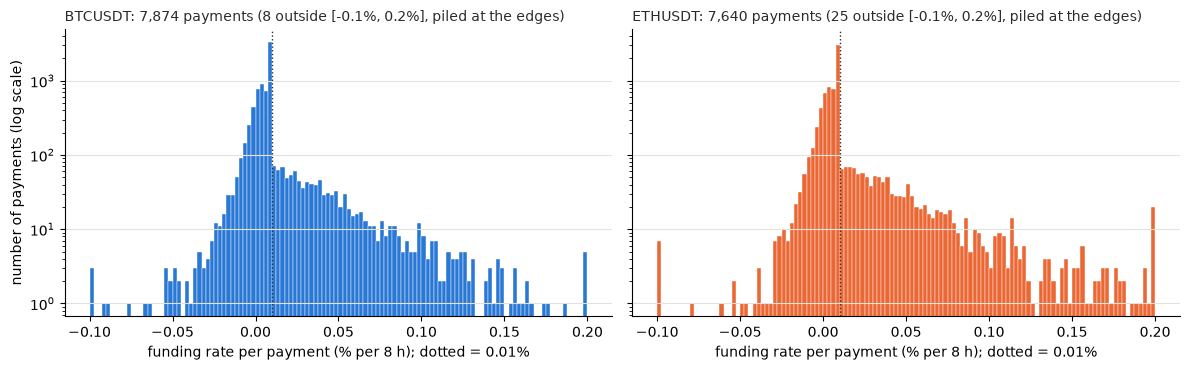

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
lo, hi = -0.10, 0.20      # % per 8 h shown; values outside are counted in the title
bins = np.arange(lo, hi + 0.0025, 0.0025)
for ax, (sym, df) in zip(axes, funding.items()):
    pct = 100 * df["funding_rate"]
    outside = int(((pct < lo) | (pct > hi)).sum())
    ax.hist(pct.clip(lo, hi), bins=bins, color=COLORS[sym], edgecolor="white", linewidth=0.3)
    ax.axvline(0.01, color=INK, lw=1, ls=":")
    ax.set_yscale("log")
    ax.set_title(f"{sym}: {len(pct):,} payments ({outside} outside [{lo}%, {hi}%], piled at the edges)",
                 loc="left", fontsize=10, color=INK)
    ax.set_xlabel("funding rate per payment (% per 8 h); dotted = 0.01%")
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("number of payments (log scale)")
plt.tight_layout()
plt.show()

How to read it: x is the rate of one payment in % per 8 h, bins of 0.0025 percentage points; y is
how many payments fall in each bin, on a **log scale** (each gridline is 10× the one below), so a
tall bar can be thousands of payments and a short one a handful. Payments outside the shown range
are clipped into the first or last bin.

## 8. Q6 · Zoom on the 10/10 crash (2025-09-15 → 2025-10-31)

(a) A public figure (FTI Consulting) says funding went from **~10% to ~30% annualized by Oct 6**.
That figure aggregates several exchanges; here we measure only Binance, with a **sweep of averaging
windows** instead of picking one: a single payment, the UTC-day mean, a trailing 3-day mean (9
payments) and a trailing 7-day mean (21 payments). Trailing means are computed on the full history,
so the first days of the zoom already have a complete window.

(b) How many negative payments came after the crash, and from when?

In [11]:
WINDOWS = {"single payment": 1, "trailing 3 days (9)": 9, "trailing 7 days (21)": 21}
sweep_rows, series = [], {}
for sym, df in funding.items():
    a = 100 * df["ann_simple"]
    per_window = {name: a.rolling(n, min_periods=n).mean() for name, n in WINDOWS.items()}
    day_mean = a.resample("1D").mean()
    per_window["UTC-day mean"] = day_mean.reindex(a.index, method="ffill")  # value of that day
    series[sym] = per_window
    for name in ["single payment", "UTC-day mean", "trailing 3 days (9)", "trailing 7 days (21)"]:
        s = per_window[name]
        pre = s[(s.index >= ZOOM_START) & (s.index < CRASH_START)]
        oct6 = s.loc["2025-10-06"]
        sweep_rows.append({"symbol": sym, "window": name,
                           "at 2025-09-15 00:00": round(s.loc[ZOOM_START:].iloc[0], 1),
                           "on Oct 6 (min–max)": f"{oct6.min():.1f}–{oct6.max():.1f}",
                           "max before crash": round(pre.max(), 1),
                           "max at (UTC)": fmt(pre.idxmax()),
                           "≥ 30% at any point before crash": bool((pre >= 30).any())})
pd.DataFrame(sweep_rows).set_index(["symbol", "window"])

at 2025-09-15 00:00 on Oct 6 (min–max)  max before crash      max at (UTC)  \
symbol  window                                                                                             
BTCUSDT single payment                        6.8           6.4–10.6              11.0  2025-10-03 16:00   
        UTC-day mean                          8.3            8.5–8.5              10.9  2025-10-03 00:00   
        trailing 3 days (9)                   4.5           9.7–10.2              10.6  2025-10-04 08:00   
        trailing 7 days (21)                  6.0            7.8–8.6               9.6  2025-10-08 08:00   
ETHUSDT single payment                        8.1           8.6–11.0              11.0  2025-09-27 16:00   
        UTC-day mean                          6.4          10.2–10.2              11.0  2025-10-07 00:00   
        trailing 3 days (9)                   8.7            7.1–7.8              10.1  2025-10-07 16:00   
        trailing 7 days (21)                  8.0            3.6–4.6               8.2  2025-09-15 08:00   

                              ≥ 30% at any point before crash  
symbol  window                                                 
BTCUSDT single payment                                  False  
        UTC-day mean                                    False  
        trailing 3 days (9)                             False  
        trailing 7 days (21)                            False  
ETHUSDT single payment                                  False  
        UTC-day mean                                    False  
        trailing 3 days (9)                             False  
        trailing 7 days (21)                            False

How to read it: one row per (symbol, averaging window), values in % per year (simple). `at
2025-09-15` is the first value of the zoom; `on Oct 6` gives the range over the 3 payments of that
day (for the UTC-day mean the three values are equal); `max before crash` is the highest value
from 2025-09-15 up to the last payment before 20:50 UTC on Oct 10. Longer windows can only smooth
peaks away, so the single-payment row is the upper bound of the others.

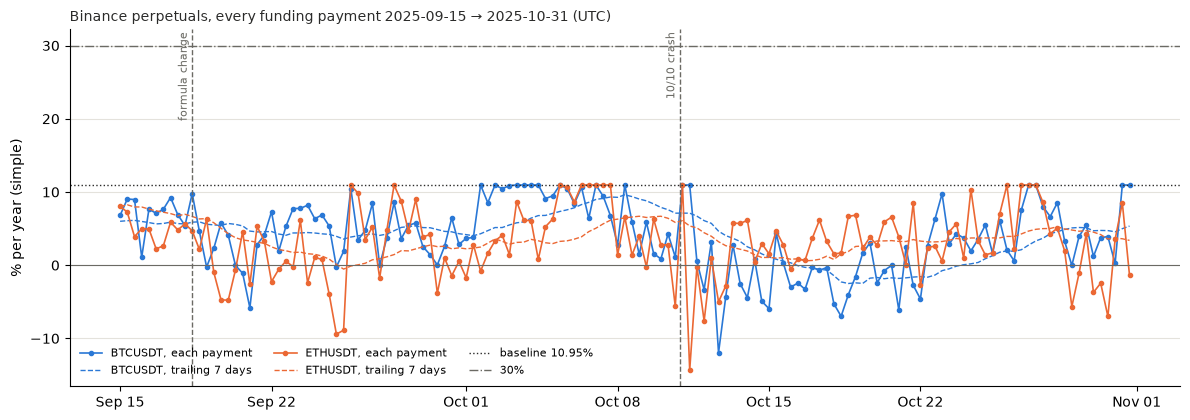

In [12]:
fig, ax = plt.subplots(figsize=(12, 4.3))
for sym, df in funding.items():
    z = 100 * df.loc[ZOOM_START:ZOOM_END - pd.Timedelta(milliseconds=1), "ann_simple"]
    ax.plot(z.index, z, color=COLORS[sym], lw=1.2, marker="o", ms=3, label=f"{sym}, each payment")
    t7 = series[sym]["trailing 7 days (21)"].loc[z.index[0]:z.index[-1]]
    ax.plot(t7.index, t7, color=COLORS[sym], lw=1.0, ls="--", label=f"{sym}, trailing 7 days")
ax.axhline(10.95, color=INK, lw=1, ls=":", label="baseline 10.95%")
ax.axhline(30, color=MUTED, lw=1, ls="-.", label="30%")
ax.axhline(0, color=MUTED, lw=0.8)
for name in ["formula change", "10/10 crash"]:
    ax.axvline(to_utc(EVENTS[name]), color=MUTED, lw=1, ls="--")
    ax.annotate(name, (to_utc(EVENTS[name]), 1), xycoords=("data", "axes fraction"), rotation=90,
                ha="right", va="top", fontsize=8, color=MUTED, xytext=(-2, -2), textcoords="offset points")
ax.set_ylabel("% per year (simple)")
ax.set_title("Binance perpetuals, every funding payment 2025-09-15 → 2025-10-31 (UTC)", loc="left",
             fontsize=10, color=INK)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.grid(axis="y", color=GRID, lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(fontsize=8, frameon=False, ncols=3, loc="lower left")
plt.tight_layout()
plt.show()

How to read it: x is the payment time (UTC); y is the simple annualized rate in % per year. Dots
joined by a solid line are individual payments (3 per day); the dashed line of the same color is
the trailing 7-day mean. Dotted line: baseline 10.95%; dash-dot line: the 30% of the public
figure. Points sitting exactly on the dotted line are payments of exactly 0.01%.

In [13]:
neg_rows, neg_lists = {}, {}
for sym, df in funding.items():
    z = df.loc[ZOOM_START:ZOOM_END - pd.Timedelta(milliseconds=1)]
    before, after = z[z.index < CRASH_START], z[z.index >= CRASH_START]
    neg = after[after["funding_rate"] < 0]
    neg_rows[sym] = {
        "payments before crash (from 09-15)": len(before),
        "above 0.01% before crash": int((before["funding_rate"] > 0.0001).sum()),
        "= 0.01% before crash": int(before["is_baseline"].sum()),
        "negative before crash": int((before["funding_rate"] < 0).sum()),
        "payments after crash (to 10-31)": len(after),
        "negative after crash": len(neg),
        "first negative (UTC)": fmt(neg.index[0]) if len(neg) else "—",
        "last negative (UTC)": fmt(neg.index[-1]) if len(neg) else "—",
        "most negative (% per 8 h)": f"{100 * neg['funding_rate'].min():.5f}" if len(neg) else "—",
        "most negative at (UTC)": fmt(neg["funding_rate"].idxmin()) if len(neg) else "—",
        "= 0.01% after crash": int(after["is_baseline"].sum()),
    }
    neg_lists[sym] = neg
pd.DataFrame(neg_rows)

,BTCUSDT,ETHUSDT
payments before crash (from 09-15),78,78
above 0.01% before crash,0,0
= 0.01% before crash,9,8
negative before crash,6,19
payments after crash (to 10-31),63,63
negative after crash,24,13
first negative (UTC),2025-10-12 00:00,2025-10-11 08:00
last negative (UTC),2025-10-29 00:00,2025-10-31 16:00
most negative (% per 8 h),-0.01091,-0.01309
most negative at (UTC),2025-10-12 16:00,2025-10-11 08:00


How to read it: one column per symbol, split at 20:50 UTC on Oct 10. Counts are numbers of payments
(3 per day). The rate is in % per 8 h (not annualized), with 4 decimals. The list below shows every
negative payment after the crash with the UTC payment time.

In [14]:
pd.concat({sym: (100 * neg["funding_rate"]).round(5).rename("rate (% per 8 h)").to_frame()
           .assign(**{"annualized (%/yr)": (100 * neg["ann_simple"]).round(1)})
           for sym, neg in neg_lists.items()}, names=["symbol"])

rate (% per 8 h)  annualized (%/yr)
symbol  funding_time_utc                                                  
BTCUSDT 2025-10-12 00:00:00.004+00:00          -0.00305               -3.3
        2025-10-12 16:00:00.000+00:00          -0.01092              -12.0
        2025-10-13 00:00:00.003+00:00          -0.00394               -4.3
        2025-10-13 16:00:00.003+00:00          -0.00231               -2.5
        2025-10-14 00:00:00.000+00:00          -0.00404               -4.4
        2025-10-14 16:00:00.000+00:00          -0.00450               -4.9
        2025-10-15 00:00:00.006+00:00          -0.00542               -5.9
        2025-10-16 00:00:00.000+00:00          -0.00274               -3.0
        2025-10-16 08:00:00.003+00:00          -0.00223               -2.4
        2025-10-16 16:00:00.002+00:00          -0.00300               -3.3
        2025-10-17 00:00:00.001+00:00          -0.00028               -0.3
        2025-10-17 08:00:00.005+00:00          -0.00063               -0.7
        2025-10-17 16:00:00.003+00:00          -0.00029               -0.3
        2025-10-18 00:00:00.000+00:00          -0.00482               -5.3
        2025-10-18 08:00:00.002+00:00          -0.00638               -7.0
        2025-10-18 16:00:00.001+00:00          -0.00368               -4.0
        2025-10-19 00:00:00.001+00:00          -0.00141               -1.5
        2025-10-20 00:00:00.004+00:00          -0.00220               -2.4
        2025-10-20 08:00:00.001+00:00          -0.00066               -0.7
        2025-10-20 16:00:00.000+00:00          -0.00002               -0.0
        2025-10-21 00:00:00.009+00:00          -0.00557               -6.1
        2025-10-21 16:00:00.000+00:00          -0.00251               -2.7
        2025-10-22 00:00:00.004+00:00          -0.00421               -4.6
        2025-10-29 00:00:00.004+00:00          -0.00003               -0.0
ETHUSDT 2025-10-11 08:00:00.003+00:00          -0.01309              -14.3
        2025-10-11 16:00:00.000+00:00          -0.00017               -0.2
        2025-10-12 00:00:00.004+00:00          -0.00696               -7.6
        2025-10-12 16:00:00.000+00:00          -0.00456               -5.0
        2025-10-13 00:00:00.003+00:00          -0.00259               -2.8
        2025-10-16 00:00:00.000+00:00          -0.00050               -0.5
        2025-10-22 00:00:00.004+00:00          -0.00249               -2.7
        2025-10-29 00:00:00.004+00:00          -0.00516               -5.6
        2025-10-29 08:00:00.005+00:00          -0.00101               -1.1
        2025-10-30 00:00:00.004+00:00          -0.00339               -3.7
        2025-10-30 08:00:00.008+00:00          -0.00224               -2.5
        2025-10-30 16:00:00.001+00:00          -0.00639               -7.0
        2025-10-31 16:00:00.007+00:00          -0.00128               -1.4

How to read it: one row per negative payment after the crash (symbol, UTC time), with the rate
per 8 h and its simple annualized value. Negative means shorts paid longs.

## 9. Q7 · Clue from notebook 04: the perp traded below spot

Notebook 04 measured the perp's last price about **4.6 bps below spot** (median of 1-minute
closes) on both Oct 9 and Oct 10. A perp below its reference usually means a negative premium,
which pushes funding down. Which funding was charged in the 6 payments of that window?

In [15]:
w04 = {sym: df.loc[W04_START:W04_END - pd.Timedelta(milliseconds=1)] for sym, df in funding.items()}
assert all(len(d) == 6 for d in w04.values()), {s: len(d) for s, d in w04.items()}
pd.concat({sym: pd.DataFrame({"rate (API text)": d["funding_rate_str"],
                              "rate (% per 8 h)": (100 * d["funding_rate"]).round(5),
                              "exactly 0.01%": d["is_baseline"],
                              "mark price": d["mark_price"].round(2)})
           for sym, d in w04.items()}, names=["symbol"])

rate (API text)  rate (% per 8 h)  exactly 0.01%  mark price
symbol  funding_time_utc                                                                          
BTCUSDT 2025-10-09 00:00:00.001+00:00      0.00001344           0.00134          False   123237.94
        2025-10-09 08:00:00.000+00:00      0.00005350           0.00535          False   121847.80
        2025-10-09 16:00:00.000+00:00      0.00001455           0.00146          False   121084.89
        2025-10-10 00:00:00.005+00:00      0.00000785           0.00078          False   121582.79
        2025-10-10 08:00:00.002+00:00      0.00003879           0.00388          False   120878.70
        2025-10-10 16:00:00.014+00:00      0.00001013           0.00101          False   118962.10
ETHUSDT 2025-10-09 00:00:00.001+00:00      0.00003613           0.00361          False     4523.67
        2025-10-09 08:00:00.000+00:00     -0.00000226          -0.00023          False     4424.43
        2025-10-09 16:00:00.000+00:00      0.00005752           0.00575          False     4313.13
        2025-10-10 00:00:00.005+00:00      0.00002565           0.00256          False     4365.89
        2025-10-10 08:00:00.002+00:00      0.00002511           0.00251          False     4321.09
        2025-10-10 16:00:00.014+00:00     -0.00005147          -0.00515          False     4100.48

How to read it: the 6 payments inside 2025-10-09 00:00 → 2025-10-11 00:00 UTC per symbol (the
payment of Oct 11 00:00 is outside: the end is excluded). `rate (API text)` is the exact string sent
by Binance; `exactly 0.01%` compares it with `Decimal`. `mark price` is the mark at that payment
(USDT per coin), used in Q8 to turn rates into USDT.

### Premium index vs last − spot (optional, cheap)

Binance publishes 1-minute candles of the **premium index** (`GET /fapi/v1/premiumIndexKlines`; in
ccxt, `fetch_ohlcv` with `params={"price": "premiumIndex"}`), as a fraction. The premium uses
**impact prices** (the average price to fill a fixed-size order on the order book) against the
**index** (a weighted spot price across several exchanges); notebook 04's gap uses the **last trade**
of the perp against Binance **spot** only. Different measures, so they need not agree.

We download the premium from **2025-10-08 16:00** (so the first payment, Oct 9 00:00, has its
whole 8-hour interval) to 2025-10-11 00:00. For each payment at time T we average the 1-minute
premium closes of `[T − 8 h, T)` in two ways: a plain mean, and the **linearly weighted** mean that
Binance's funding FAQ describes (later minutes weigh more: weights 1, 2, …, n; not re-verified this
session). Then we apply the formula `P + clamp(0.01% − P, ±0.05%)`. This is an approximation:
Binance samples the premium every few seconds, we only have one value per minute. The payment of
Oct 11 00:00 (just outside 04's window) is included because its interval contains the crash.

In [16]:
PREM_START = to_utc("2025-10-08 16:00")
prem_path = cache_path(CACHE_DIR, "binanceusdm", "BTC/USDT:USDT", "1m", "oct8_16h-oct10",
                       price="premiumIndex")
prem, prem_info = load_or_fetch_window(prem_path, lambda: fetch_ohlcv_window(
    "binanceusdm", "BTC/USDT:USDT", PREM_START, W04_END, price="premiumIndex"))
expected = pd.date_range(PREM_START, W04_END - pd.Timedelta(minutes=1), freq="1min")
assert prem.index.equals(expected), "premium index: missing or extra minutes"

btc = funding["BTCUSDT"]
pay_times = btc.loc[W04_START:W04_END + pd.Timedelta(minutes=1)].index  # 6 + Oct 11 00:00 (ms offsets!)
assert len(pay_times) == 7
rows = {}
for t in pay_times:
    t0 = t.floor("min")   # payment times can be a few ms after the minute
    p = prem.loc[t0 - pd.Timedelta(hours=8):t0 - pd.Timedelta(minutes=1), "close"]
    assert len(p) == 480
    weights = np.arange(1, len(p) + 1)
    p_mean, p_weighted = p.mean(), np.average(p, weights=weights)
    rows[fmt(t)] = {"minutes": len(p),
                    "premium mean (%)": 100 * p_mean, "premium weighted (%)": 100 * p_weighted,
                    "formula, mean (%)": 100 * binance_funding_from_premium(p_mean),
                    "formula, weighted (%)": 100 * binance_funding_from_premium(p_weighted),
                    "published (%)": 100 * btc.loc[t, "funding_rate"],
                    "in dead zone [−0.04%, +0.06%]": bool(-0.0004 <= p_weighted <= 0.0006)}
q7 = pd.DataFrame(rows).T
q7.index.name = "BTCUSDT payment (UTC)"
q7["weighted − published (pp)"] = q7["formula, weighted (%)"] - q7["published (%)"]
q7.round(5)

,minutes,premium mean (%),premium weighted (%),"formula, mean (%)","formula, weighted (%)",published (%),"in dead zone [−0.04%, +0.06%]",weighted − published (pp)
BTCUSDT payment (UTC),,,,,,,,
2025-10-09 00:00,480,-0.047111,-0.049103,0.002889,0.000897,0.001344,False,-0.000447
2025-10-09 08:00,480,-0.044176,-0.044258,0.005824,0.005742,0.00535,False,0.000392
2025-10-09 16:00,480,-0.045285,-0.046328,0.004715,0.003672,0.001455,False,0.002217
2025-10-10 00:00,480,-0.049136,-0.049357,0.000864,0.000643,0.000785,False,-0.000142
2025-10-10 08:00,480,-0.047322,-0.046327,0.002678,0.003673,0.003879,False,-0.000206
2025-10-10 16:00,480,-0.047164,-0.047817,0.002836,0.002183,0.001013,False,0.00117
2025-10-11 00:00,480,-0.034053,-0.028782,0.01,0.01,0.01,True,-0.0


How to read it: one row per BTCUSDT payment; all values in % per 8 h. `premium mean` and
`premium weighted` are the two averages of the 1-minute premium over the 8 hours before the payment
(negative = perp below the index). `formula, weighted` applies Binance's formula to the weighted
average; `published` is what Binance charged. `in dead zone` says whether the weighted premium falls
in [−0.04%, +0.06%], where the formula returns exactly 0.01% whatever the premium.

Below: the same day-by-day comparison as notebook 04 — median over the 1,440 minutes of each day,
in bps (1 bp = 0.01%) — of the premium index close and of notebook 04's `(perp last close / spot
close − 1)`.

In [17]:
SERIES_04 = {"perp last": ("binanceusdm", "BTC/USDT:USDT", None),
             "perp mark": ("binanceusdm", "BTC/USDT:USDT", "mark"),
             "spot last": ("binance", "BTC/USDT", None)}
frames = {}
for name, (ex_id, symbol, price) in SERIES_04.items():
    path = cache_path(CACHE_04, ex_id, symbol, "1m", "oct9-10", price=price)
    frames[name], _ = load_or_fetch_window(path, lambda ex_id=ex_id, symbol=symbol, price=price:
                                           fetch_ohlcv_window(ex_id, symbol, W04_START, W04_END, price=price))
    # exact coverage, as in notebook 04: a cache from another window must fail here
    assert frames[name].index.equals(pd.date_range(W04_START, W04_END - pd.Timedelta(minutes=1),
                                                   freq="1min")), name
last, mark, spot = (frames[n] for n in SERIES_04)

gap_bps = 10_000 * (last["close"] / spot["close"] - 1)
prem_bps = 10_000 * prem.loc[W04_START:, "close"]
compare = pd.DataFrame({
    day: {"last − spot, median (bps)": gap_bps.loc[day].median(),
          "premium index, median (bps)": prem_bps.loc[day].median(),
          "premium index, p5 (bps)": prem_bps.loc[day].quantile(0.05),
          "premium index, p95 (bps)": prem_bps.loc[day].quantile(0.95),
          "minutes with premium < −4 bps (%)": 100 * (prem_bps.loc[day] < -4).mean()}
    for day in ["2025-10-09", "2025-10-10"]}).T
compare.round(2)

,"last − spot, median (bps)","premium index, median (bps)","premium index, p5 (bps)","premium index, p95 (bps)",minutes with premium < −4 bps (%)
2025-10-09,-4.56,-4.62,-6.36,-2.73,72.64
2025-10-10,-4.60,-4.60,-6.89,-0.62,71.18


How to read it: one row per UTC day of notebook 04's window; bps. The first column reproduces
notebook 04's measurement; the next three describe the premium index (median and the 5th / 95th
percentiles of its 1,440 one-minute values). The last column is the share of minutes in which the
premium was below −4 bps = −0.04%, the lower edge of the dead zone.

## 10. Q8 · Clue from notebook 04: the real cost of funding

**(a) Payments.** A long of 5,000 / 10,000 / 20,000 USDT notional that stays open through all 6
payments of 04's window. Notebook 04 assumed 6 × 0.01% = 0.06% of notional. Here: the same with
the real BTCUSDT rates, in two ways — constant notional (`notional × Σ rates`), and fixed size in
BTC (`qty × Σ markₖ × rateₖ`, with `qty = notional / entry` and, as reference entry, the mark of the
first payment), which is how the exchange charges (notional at the mark of each payment).

In [18]:
b04 = w04["BTCUSDT"]
rates, marks = b04["funding_rate"].to_numpy(), b04["mark_price"].to_numpy()
assert not np.isnan(marks).any()
entry_ref = marks[0]
pay_rows = {}
for lev, notional in NOTIONALS.items():
    qty = notional / entry_ref
    pay_rows[f"{lev}x ({notional:,.0f} USDT)"] = {
        "assumed: 6 × 0.01% (USDT)": 6 * funding_payment("long", notional, ASSUMED_RATE),
        "real, constant notional (USDT)": float(funding_payment("long", notional, rates).sum()),
        "real, fixed qty at each mark (USDT)": total_funding_paid("long", qty, marks, rates),
        "as % of the 1,000 margin": 100 * total_funding_paid("long", qty, marks, rates) / MARGIN}
print(f"sum of the 6 real rates: {100 * rates.sum():.5f}% (assumed 0.06%)")
pd.DataFrame(pay_rows).T.round(3)

sum of the 6 real rates: 0.01383% (assumed 0.06%)


,assumed: 6 × 0.01% (USDT),"real, constant notional (USDT)","real, fixed qty at each mark (USDT)","as % of the 1,000 margin"
"5x (5,000 USDT)",3.0,0.691,0.681,0.068
"10x (10,000 USDT)",6.0,1.383,1.362,0.136
"20x (20,000 USDT)",12.0,2.765,2.724,0.272


How to read it: one row per leverage (all with 1,000 USDT margin); USDT paid by the long over the 6
payments (positive = paid, negative = received). The first column is notebook 04's assumption; the
next two use the real rates. The last column puts the real cost next to the margin it would eat.

**(b) Sensitivity, post-inspection: funding taken out of the isolated margin.** Pessimistic test:
every simulated position of notebook 04 pays all 6 real payments (even those before its entry),
and the total `qty × Σ markₖ × rateₖ` is taken out of its isolated margin **from the entry on**
(not verified that Binance deducts funding from isolated margin this way). That raises every LP.

**Could the design produce a different result?** Before running it: 10x and 20x were already
**100%** liquidated, and a smaller margin can only raise the LP, so their counts **cannot** change;
only their *timing* can. 5x was **0%** liquidated; it changes only if funding moves the highest 5x
LP up to the mark's minimum of the window. The cell computes how much funding that would take
(break-even) and compares it with what was paid.

In [19]:
entry_close = last.loc["2025-10-09 00:00":"2025-10-09 23:59", "close"]
assert len(entry_close) == 1_440
funding_per_qty = float(np.sum(marks * rates))          # USDT per 1 BTC over the 6 payments
lows = {"mark": mark["low"]}
base = simulate_isolated_longs(entry_close, lows, LEVERAGES, MARGIN, MMR, CUM)
paid = simulate_isolated_longs(entry_close, lows, LEVERAGES, MARGIN, MMR, CUM,
                               funding_per_qty=funding_per_qty)
PLATEAU = to_utc("2025-10-10 19:30")      # split used in notebook 04 (20x before / at the crash)
sens = {}
for lev in LEVERAGES:
    b, p = base.xs(lev, level="leverage"), paid.xs(lev, level="leverage")
    sens[lev] = {"funding paid, mean (USDT)": p["funding_paid"].mean(),
                 "LP shift, mean (USDT)": (p["lp"] - b["lp"]).mean(),
                 "liquidated, base (%)": 100 * b["liquidated_mark"].notna().mean(),
                 "liquidated, with funding (%)": 100 * p["liquidated_mark"].notna().mean(),
                 "before 19:30, base": int((b["liquidated_mark"] <= PLATEAU).sum()),
                 "before 19:30, with funding": int((p["liquidated_mark"] <= PLATEAU).sum()),
                 "liquidated earlier": int((p["liquidated_mark"] < b["liquidated_mark"]).sum())}
sens = pd.DataFrame(sens).T
sens.index.name = "leverage"

# Break-even for 5x: funding per BTC that would lift the highest 5x LP to the mark's minimum.
# Long LP = (q·E − m') / (q·(1 − MMR))  ⇒  LP = mark_min when m' = q·E − mark_min·q·(1 − MMR).
five = base.xs(5, level="leverage")
mark_min = mark["low"].min()
needed_per_qty = (MARGIN / five["qty"] - five["entry"] + mark_min * (1 - MMR)).min()
print(f"funding paid per BTC over the 6 payments: {funding_per_qty:.2f} USDT "
      f"(≈ {100 * funding_per_qty / marks.mean():.4f}% of the mean mark)")
print(f"5x break-even: {needed_per_qty:,.0f} USDT per BTC ≈ {100 * needed_per_qty / marks.mean():.2f}% "
      f"of the mean mark ≈ {needed_per_qty / (ASSUMED_RATE * marks.mean()):,.0f} payments of 0.01%; "
      f"{needed_per_qty / funding_per_qty:,.0f}× what was paid")
sens.round(2)

funding paid per BTC over the 6 payments: 16.79 USDT (≈ 0.0138% of the mean mark)
5x break-even: 2,546 USDT per BTC ≈ 2.10% of the mean mark ≈ 210 payments of 0.01%; 152× what was paid


,"funding paid, mean (USDT)","LP shift, mean (USDT)","liquidated, base (%)","liquidated, with funding (%)","before 19:30, base","before 19:30, with funding",liquidated earlier
leverage,,,,,,,
5,0.69,16.85,0.0,0.0,0.0,0.0,0.0
10,1.38,16.85,100.0,100.0,0.0,0.0,24.0
20,2.76,16.85,100.0,100.0,874.0,882.0,139.0


How to read it: one row per leverage, 1,440 positions each, liquidation by the mark as in notebook
04. `funding paid` is the USDT taken out of each margin; `LP shift` is how many USDT the liquidation
price moved up. The `liquidated` columns are % of positions; `before 19:30` counts positions
liquidated before 19:30 UTC on Oct 10 (notebook 04's split of the 20x liquidations); `liquidated
earlier` counts positions whose liquidation minute moved earlier. The printed break-even is the
funding (USDT per BTC of position) that would have been needed to liquidate even one 5x position.

## 11. Q9 · Domain check (M7): one week at +0.05% per 8 h

A long of **10,000 USDT** notional, funding **+0.05%** every 8 hours, for **one week**: 7 days × 3 =
21 payments × (10,000 × 0.0005 = 5 USDT) = **105 USDT** paid (1.05% of notional per week, 54.75% per
year, simple). Then, with real data: how many BTCUSDT payments were **≥ 0.05%**, and when?

In [20]:
week = 21 * funding_payment("long", 10_000, 0.0005)
assert abs(week - 105.0) < 1e-9
print(f"one week at +0.05% per 8 h on 10,000 USDT: {week:.2f} USDT paid by the long")

btc = funding["BTCUSDT"]
high = btc[[Decimal(s) >= Decimal("0.0005") for s in btc["funding_rate_str"]]]
print(f"BTCUSDT payments ≥ 0.05%: {len(high)} of {len(btc):,} ({100 * len(high) / len(btc):.2f}%); "
      f"first {fmt(high.index.min())}, last {fmt(high.index.max())} UTC")
by_month = high.groupby(high.index.strftime("%Y-%m")).agg(
    payments=("funding_rate", "size"), max_rate_pct=("funding_rate", lambda r: 100 * r.max()))
by_month.index.name = "month (UTC)"
by_month.round(4)

one week at +0.05% per 8 h on 10,000 USDT: 105.00 USDT paid by the long
BTCUSDT payments ≥ 0.05%: 333 of 7,874 (4.23%); first 2019-10-28 08:00, last 2024-12-05 08:00 UTC


,payments,max_rate_pct
month (UTC),,
2019-10,4,0.0784
2020-01,11,0.1082
2020-02,40,0.3000
2020-03,1,0.0547
2020-04,1,0.0975
2020-05,3,0.0758
2020-06,1,0.0783
2020-07,13,0.1395
2020-08,9,0.1319


How to read it: the first line checks the hand calculation. The table groups the BTCUSDT payments
of at least 0.05% by calendar month (UTC): how many there were and the largest rate of that month,
in % per 8 h. Months not listed had none.

## 12. Q10 · Cap and floor

`GET /fapi/v1/fundingInfo` (measured in Step 0) gives the current cap/floor and interval for symbols
with adjusted parameters. A third party (not official) says **±0.3% per 8 h** for BTCUSDT. Did any
payment reach it?

In [21]:
finfo = pd.DataFrame({sym: source_checks["fundingInfo"][sym] for sym in SYMBOLS})
print(f"symbols listed by fundingInfo: {source_checks['fundingInfo']['symbols listed']}")
display(finfo)
extremes = {}
for sym, df in funding.items():
    cap = Decimal(source_checks["fundingInfo"][sym]["adjustedFundingRateCap"])
    floor = Decimal(source_checks["fundingInfo"][sym]["adjustedFundingRateFloor"])
    values = [Decimal(s) for s in df["funding_rate_str"]]
    extremes[sym] = {"max rate (% per 8 h)": f"{100 * df['funding_rate'].max():.4f}",
                     "max at (UTC)": fmt(df["funding_rate"].idxmax()),
                     "min rate (% per 8 h)": f"{100 * df['funding_rate'].min():.4f}",
                     "min at (UTC)": fmt(df["funding_rate"].idxmin()),
                     "payments at or above cap": sum(v >= cap for v in values),
                     "payments at or below floor": sum(v <= floor for v in values)}
pd.DataFrame(extremes)

symbols listed by fundingInfo: 824


,BTCUSDT,ETHUSDT
symbol,BTCUSDT,ETHUSDT
adjustedFundingRateCap,0.00300,0.00300
adjustedFundingRateFloor,-0.00300,-0.00300
fundingIntervalHours,8,8
disclaimer,True,True
updateTime,None,None


,BTCUSDT,ETHUSDT
max rate (% per 8 h),0.3000,0.3750
max at (UTC),2020-02-12 00:00,2021-01-04 08:00
min rate (% per 8 h),-0.3000,-0.3563
min at (UTC),2020-03-13 08:00,2021-05-19 16:00
payments at or above cap,1,3
payments at or below floor,1,2


How to read it: the first table is `fundingInfo` as returned (cap and floor as fractions per
interval: 0.003 = 0.3%; `fundingIntervalHours`; `disclaimer`; `updateTime`). The second gives, per
symbol, the highest and lowest rate in the whole history and how many payments touched the cap or
the floor. `fundingInfo` is a **snapshot of today**: it does not say what the cap was in 2019–2025.

## Conclusions (key takeaways)

Binance only, BTCUSDT and ETHUSDT, 2019-09-10 → 2026-11-16 UTC. Each conclusion gives the number of
observations behind it and asks whether the design could have produced a different result.

1. **Clean data, one schedule.** 7,874 BTCUSDT and 7,640 ETHUSDT payments; every one of the
   7,873 / 7,639 intervals is 8 h (raw deviations −45 to +47 ms), with 0 gaps, 0 duplicates and 0
   "Special" rows, so the simple annualization (× 1,095) is valid for every record.
   *Could the design show otherwise?* Yes: intervals are measured on raw timestamps, and a 4-hour
   period would have appeared as its own row (465 of the 824 symbols in `fundingInfo` use 4 h today).
2. **The 0.01% "dead zone" is the most common single value, but not the usual state, and it is
   fading.** Exactly 0.01%: **34.90%** of BTCUSDT payments (2,748 / 7,874) and **33.86%** of ETHUSDT
   payments, in line with the third-party ~35%. The share barely moves with the tolerance (BTC 35.12% at
   1e-6). By year, BTC's share fell from **66.9%** (2019) to **17.2%** (2025) and **9.1%** (2026);
   85.84% of all BTC payments were positive. *Could the design show otherwise?* Yes: the comparison is
   exact (`Decimal` on the API text) and any share from 0 to 100% was possible. The post-inspection
   sweep finds a lower share after 2025-09-18 in all 4 windows (BTC 7.0–12.2% after vs 16.7–33.3%
   before). The "before" values vary widely between windows, though, so this shows timing, not a cause.
3. **Before the crash, Binance never showed the ~30% of the public figure.** From 2025-09-15 to
   20:50 UTC on 2025-10-10, **0 of 78** payments per symbol were above 0.01%; the highest value was
   **11.0%/yr** (= 0.01%) for every window in the sweep (single payment, UTC day, 3 days, 7 days).
   *Could the design show otherwise?* Yes: the same measure finds **333** BTCUSDT payments ≥ 0.05%
   (54.75%/yr) in the history, the last on 2024-12-05. The public ~30% is a multi-exchange aggregate,
   so this is a statement about Binance only. After the crash, **24 of 63** BTCUSDT payments (first
   2025-10-12 00:00) and **13 of 63** ETHUSDT payments (first 2025-10-11 08:00) were negative. They were
   small (lowest −0.01091% and −0.01309% per 8 h, about −12% and −14%/yr), and negatives were not new:
   **6** (BTC) and **19** (ETH) of the 78 payments before the crash were negative too.
4. **Notebook 04's "perp below spot" shows up in the funding, and the formula explains it.** **0 of
   the 6** BTCUSDT payments of 04's window were 0.01%. All were positive but lower (0.00078% to 0.00535%;
   sum **0.01383%** vs the assumed 0.06%). The premium index (median **−4.62 / −4.60 bps** on Oct 9 / 10)
   matched 04's last − spot (**−4.56 / −4.60 bps**). Its weighted 8-hour average (−0.0443% to −0.0494%)
   sat just **below the dead zone's lower edge (−0.04%)**, so F = P + 0.05%. That rebuilds the published
   rate to within **0.0022 percentage points** in all 6 payments. *Could the design show otherwise?*
   Yes: the very next payment (2025-10-11 00:00, premium −0.0288%, inside the zone) was exactly
   0.01%.
5. **Funding did not change notebook 04's result, and in that window it could not have.** Real
   funding cost a surviving long **0.68 / 1.36 / 2.72 USDT** (5x / 10x / 20x), about 4.3× less than the
   assumed 3 / 6 / 12. Taking it out of the isolated margin (pessimistic) lifts every LP by **16.85
   USDT**. Liquidations stay **0% / 100% / 100%** of 1,440 each; the only change is 20x liquidations
   before 19:30 UTC: **874 → 882**. *Could the design show otherwise?* Not for 10x/20x: they were already
   at 100%, and less margin only raises LP. For 5x, it would have needed **2,546 USDT per BTC**
   (≈ 210 payments of 0.01%, **152×** what was paid).

**Hypothesis check.** "Exactly 0.01% most of the time": **not supported**. It is the most common
single value (34.90% BTC, 33.86% ETH) but not most payments, and the share fell to 9.1% in 2026.
"Above 0.01% in bull runs, negative after crashes": **consistent with the history** (BTC's yearly mean
was 30.61%/yr in 2021; the lowest daily mean, −139.2%/yr, was on 2020-03-13), but not tested
statistically. The 10/10 crash was followed by only mildly negative funding.

## Open questions

- **Why did the share of exact 0.01% payments collapse in 2025–2026, and why did BTCUSDT trade
  persistently ~0.045% below its index in October 2025?** A candidate (not tested): more
  delta-neutral capital (long spot + short perp, e.g. the basis trade or synthetic-dollar products)
  pushes the perp below the index. Testing it would need open interest and positioning data.
- **Where does the public ~30% come from?** It aggregates several exchanges; reproducing it would
  need their funding histories (Bybit, OKX, others) and the same averaging method.
- **Historical caps.** `fundingInfo` is a snapshot: ±0.3% for both symbols today. BTCUSDT touched
  exactly +0.3000% (2020-02-12 00:00) and −0.3000% (2020-03-13 08:00); ETHUSDT reached +0.3750%
  (2021-01-04) and −0.3563% (2021-05-19), **beyond** today's ±0.3%, so its cap was different
  back then. The ±0.3% of the third-party source matches today's `fundingInfo`, but no official history of
  the caps was found. The meaning of `"disclaimer": true` is not documented on the endpoint page.
- **Does Binance take funding out of the isolated margin?** Q8 assumed it (pessimistic). The answer
  does not change 04's counts, but it matters for positions held for weeks.
- **Premium sampling.** We rebuilt the rate from 1-minute premium closes; Binance samples every few
  seconds. Is the remaining difference (≤ 0.0022 percentage points) only sampling, or also the
  weighting?
- **ETH's lowest daily funding (−193.2%/yr) was on 2022-09-15**, the day of the Ethereum Merge.
  Timing alone does not show a cause.